In [ ]:
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

from pyrite.units import Q_, ureg

# This notebook teaches configuration and post-processing only: no
# electron transport, backend selection, or reference-table download.

# Units and quantities in PyRITE

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/00a-units-and-quantities.py)

PyRITE uses [Pint](https://pint.readthedocs.io/) to validate many physical
**inputs**, but its numerical kernels and saved arrays generally use plain
numbers in **documented canonical units**. In this tutorial you will:

1. Construct and convert scalar and array quantities.
2. Configure a beam, crystal and detector using several different units.
3. Read back quantities, update immutable objects, and catch unit errors.
4. Distinguish *energy-coordinate units* from *spectral-density units*, and
   *beam current* from *sampled Monte Carlo histories*.

No simulation is run. The spectrum below is **synthetic**, solely to
illustrate the units of a real PyRITE result interface. The notebook runs
on CPU without downloading reference tables.

## 1. The shared unit registry

Always construct quantities using `pyrite.units.ureg` (or its `Q_` alias).
A quantity combines a **magnitude** with a **unit**. `.to(...)` returns a
converted quantity; `.magnitude` strips the units and should be used only
when an API explicitly requires a plain number. Do not alter the shared
registry's unit definitions.

**Common units:** electron kinetic and photon energy: eV, keV, MeV;
crystal thickness and lattice lengths: Å (`angstrom`), nm, µm; transverse
geometry: mm; polar/azimuthal angle: degrees or radians; solid angle: sr;
bunch time: fs/ps; charge: pC; repetition rate: Hz/kHz; exposure: s.

In [ ]:
electron_energy = 0.03 * ureg.MeV
target_thickness = Q_(100, "nm")
observation_angle = (3 * np.pi / 4) * ureg.radian

assert np.isclose(electron_energy.to("keV").magnitude, 30)
assert np.isclose(target_thickness.to("angstrom").magnitude, 1_000)
assert np.isclose(observation_angle.to("degree").magnitude, 135)

conversions = {
    "electron energy": f"{electron_energy:~P} = {electron_energy.to('keV'):~P}",
    "target thickness": f"{target_thickness:~P} = {target_thickness.to('angstrom'):~P}",
    "observation angle": f"{observation_angle:~P} = {observation_angle.to('degree'):~P}",
}
print(*(f"{k}: {v}" for k, v in conversions.items()), sep="\n")  # display unit conversions

electron energy: 0.03 MeV = 30.0 keV
target thickness: 100 nm = 1000.0 Å
observation angle: 2.356194490192345 rad = 135.0 deg


## 2. Arrays and dimensional arithmetic

A single Pint quantity can wrap a NumPy array. Convert the entire array
before extracting numeric magnitudes. Arithmetic also carries units:
charge × repetition frequency is an **electric current**, while a length
divided by a time is a **speed**. The angular unit `radian` is special:
radians and steradians are dimensionless in SI, but PyRITE **explicitly
checks for a real angle unit** on its semantic angle inputs.

In [ ]:
kinetic_energies = Q_(np.array([10.0, 30.0, 60.0]), "keV")
energy_nodes_eV = kinetic_energies.to("eV").magnitude
assert np.array_equal(energy_nodes_eV, [10_000.0, 30_000.0, 60_000.0])

bunch_charge = 0.5 * ureg.pC
pulse_rate = 100 * ureg.kHz
average_current = (bunch_charge * pulse_rate).to("nA")
assert np.isclose(average_current.magnitude, 50.0)

array_and_current = {
    "energies (eV)": energy_nodes_eV.tolist(),
    "bunch charge": str(bunch_charge),
    "repetition rate": str(pulse_rate),
    "average current": str(average_current),
}
print(*(f"{k}: {v}" for k, v in array_and_current.items()), sep="\n")  # display calculated values

energies (eV): [10000.0, 30000.0, 60000.0]
bunch charge: 0.5 picocoulomb
repetition rate: 100 kilohertz
average current: 49.99999999999999 nanoampere


## 3. Quantities at public configuration boundaries

The **semantic** input spellings (`kinetic_energy`, `thickness`, `tilt`,
`observation_angle`, `width`) require Pint quantities. Equivalent choices
of input unit produce the same **canonical numeric fields** used internally.
The matching semantic properties return fresh quantities for convenient
conversion; this does **not** mean Pint values enter transport kernels.

Keep the two naming styles distinct:

| Quantity-aware spelling | Existing numeric field | Canonical numeric unit |
| --- | --- | --- |
| `Beam.kinetic_energy` | `Beam.energy_keV` | keV |
| `Slab.thickness` | `Slab.thickness_ang` | Å |
| `Slab.tilt` | `Slab.tilt_deg` | degree |
| `Footprint.width` | `Footprint.width_mm` | mm |
| `Detector.observation_angle` | `Detector.observation_angle_deg` | degree |

`Slab.thickness` is a **physical thickness**, not an electron transport
step length. `Footprint.width` is the *full* transverse width, not a half
width or standard deviation. Detector polar angle is measured from the
beam axis; it is not a solid-angle acceptance.

In [ ]:
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.detectors import Detector
from pyrite.geometry import Footprint, Slab

beam = Beam(
    kinetic_energy=0.03 * ureg.MeV,
    transverse=PointSpot(),
    longitudinal=PointBunch(),
)
target = Slab(
    "hopg",
    thickness=0.1 * ureg.um,
    tilt=(np.pi / 6) * ureg.radian,
    footprint=Footprint(width=0.5 * ureg.cm, height=5 * ureg.mm),
)
detector = Detector(observation_angle=0.75 * np.pi * ureg.radian)

assert np.isclose(beam.energy_keV, 30)
assert np.isclose(target.thickness_ang, 1_000)
assert np.isclose(target.tilt_deg, 30)
assert np.isclose(target.footprint.width_mm, 5)
assert np.isclose(detector.observation_angle_deg, 135)
assert np.isclose(beam.kinetic_energy.to("eV").magnitude, 30_000)
assert np.isclose(target.thickness.to("nm").magnitude, 100)

canonical_fields = {
    "energy_keV": beam.energy_keV,
    "thickness_ang": target.thickness_ang,
    "tilt_deg": target.tilt_deg,
    "footprint width_mm": target.footprint.width_mm,
    "observation_angle_deg": detector.observation_angle_deg,
}
print(
    *(f"{k}: {v}" for k, v in canonical_fields.items()), sep="\n"
)  # inspect the numeric representation

energy_keV: 30.0
thickness_ang: 1000.0
tilt_deg: 29.999999999999996
footprint width_mm: 5.0
observation_angle_deg: 135.0


## 4. Make changes without discarding units

Most configuration objects are immutable. Rather than assigning to an
internal numeric field, use the corresponding `with_*` method for a
quantity-aware replacement. The old object is unchanged. A legacy numeric
spelling such as `energy_keV=30` also remains supported, **but its number
means exactly 30 keV**; a bare `30000` would mean 30,000 keV, not 30,000 eV.
Never provide both spellings of the *same* field in one constructor.

In [ ]:
more_energetic = beam.with_kinetic_energy(45_000 * ureg.eV)
thicker = target.with_thickness(0.25 * ureg.um)
rotated = detector.with_observation_angle(120 * ureg.degree)

assert np.isclose(beam.energy_keV, 30)  # Original unchanged
assert np.isclose(more_energetic.energy_keV, 45)
assert np.isclose(thicker.thickness.to("nm").magnitude, 250)
assert np.isclose(rotated.observation_angle_deg, 120)

replacements = {
    "original energy (keV)": beam.energy_keV,
    "replaced energy (keV)": more_energetic.energy_keV,
    "new thickness (nm)": thicker.thickness.to("nm").magnitude,
    "new polar angle (degree)": rotated.observation_angle_deg,
}
print(*(f"{k}: {v}" for k, v in replacements.items()), sep="\n")  # display immutable replacements

original energy (keV): 30.0
replaced energy (keV): 45.0
new thickness (nm): 249.99999999999997
new polar angle (degree): 120.0


## 5. Catch dimensional mistakes before simulating

Invalid dimensions, dimensionless "angles", and contradictory numeric and
semantic inputs fail **at construction**, rather than producing a subtly
wrong result. PyRITE does not assume a unit for `kinetic_energy=30` or
`thickness=100`: those semantic forms require actual quantities.

In [ ]:
checks = {
    "energy used as a length": lambda: target.with_thickness(3 * ureg.keV),
    "bare semantic energy": lambda: beam.with_kinetic_energy(30),
    "dimensionless polar angle": lambda: detector.with_observation_angle(135 * ureg.dimensionless),
    "conflicting energy spellings": lambda: type(beam)(
        energy_keV=30,
        kinetic_energy=30 * ureg.keV,
        transverse=beam.transverse,
        longitudinal=beam.longitudinal,
    ),
}
rejected = {}
for mistake, construct in checks.items():
    try:
        construct()
    except (TypeError, ValueError) as error:
        rejected[mistake] = type(error).__name__
    else:
        raise AssertionError(f"PyRITE unexpectedly accepted {mistake}")
print(
    *(f"{k}: {v}" for k, v in rejected.items()), sep="\n"
)  # all four configuration mistakes are rejected

energy used as a length: ValueError
bare semantic energy: TypeError
dimensionless polar angle: ValueError
conflicting energy spellings: TypeError


## 6. From a quantity to a numeric-only API

Some lower-level public functions intentionally take plain magnitudes,
with their unit **in the parameter name** (for example
`simulate_trajectories(E0_keV=..., thickness_ang=...)` and
`photon_energies(..., E_eV, tilt_deg=..., theta_obs_deg=...)`).
Only at these boundaries, convert then extract `.magnitude`. Do not hand
such a function a Pint quantity and hope it will guess.

In [ ]:
# Numeric arguments for a low-level transport function, not a simulation.
transport_energy_keV = (30_000 * ureg.eV).to("keV").magnitude
transport_thickness_ang = (100 * ureg.nm).to("angstrom").magnitude
assert np.isclose(transport_energy_keV, 30)
assert np.isclose(transport_thickness_ang, 1_000)
numeric_arguments = {
    "E0_keV": float(transport_energy_keV),
    "thickness_ang": float(transport_thickness_ang),
}
print(
    *(f"{k}: {v}" for k, v in numeric_arguments.items()), sep="\n"
)  # these are plain floats in documented units

E0_keV: 30.0
thickness_ang: 1000.0


## 7. Spectral densities: converting the axis is not enough

PyRITE's source `SpectralDensity` stores photon energies in **eV** and
spectral density in **photons / (incident electron · eV · sr)**. When you
change the horizontal coordinate to keV, you **must also multiply the
density by 1,000**: $f_{\mathrm{keV}}\,dE_{\mathrm{keV}}
= f_{\mathrm{eV}}\,dE_{\mathrm{eV}}$. The integral (photons per incident
electron per sr) stays unchanged.

The public `SpectralDensity.quantify().to_energy("keV")` does this
*coupled conversion* for you. It does **not** change the spectrum's
per-electron normalization, multiply by acceptance, or predict a photon
rate. `Result.spectral_flux(units="detector")` uses a different sort of
`units` argument: it selects **physical normalization**, not eV vs keV.

In [ ]:
from pyrite.results import SpectralDensity

# A synthetic Gaussian-like component, NOT a simulated PyRITE prediction.
photon_energy_eV = np.linspace(500.0, 1_500.0, 401)
density_per_eV = 1e-9 * np.exp(-0.5 * ((photon_energy_eV - 1_000) / 80) ** 2)
source = SpectralDensity(photon_energy_eV, density_per_eV)
quantified = source.quantify()
in_keV = quantified.to_energy("keV")

assert quantified.normalization == in_keV.normalization == "source"
assert np.allclose(in_keV.photon_energy.magnitude, photon_energy_eV / 1_000)
assert np.allclose(in_keV.density.magnitude, density_per_eV * 1_000)
integral_per_eV = np.trapezoid(source.density, source.photon_energy_eV)
integral_per_keV = np.trapezoid(in_keV.density.magnitude, in_keV.photon_energy.magnitude)
assert np.isclose(integral_per_eV, integral_per_keV)
assert in_keV.photon_energy.units == ureg.keV

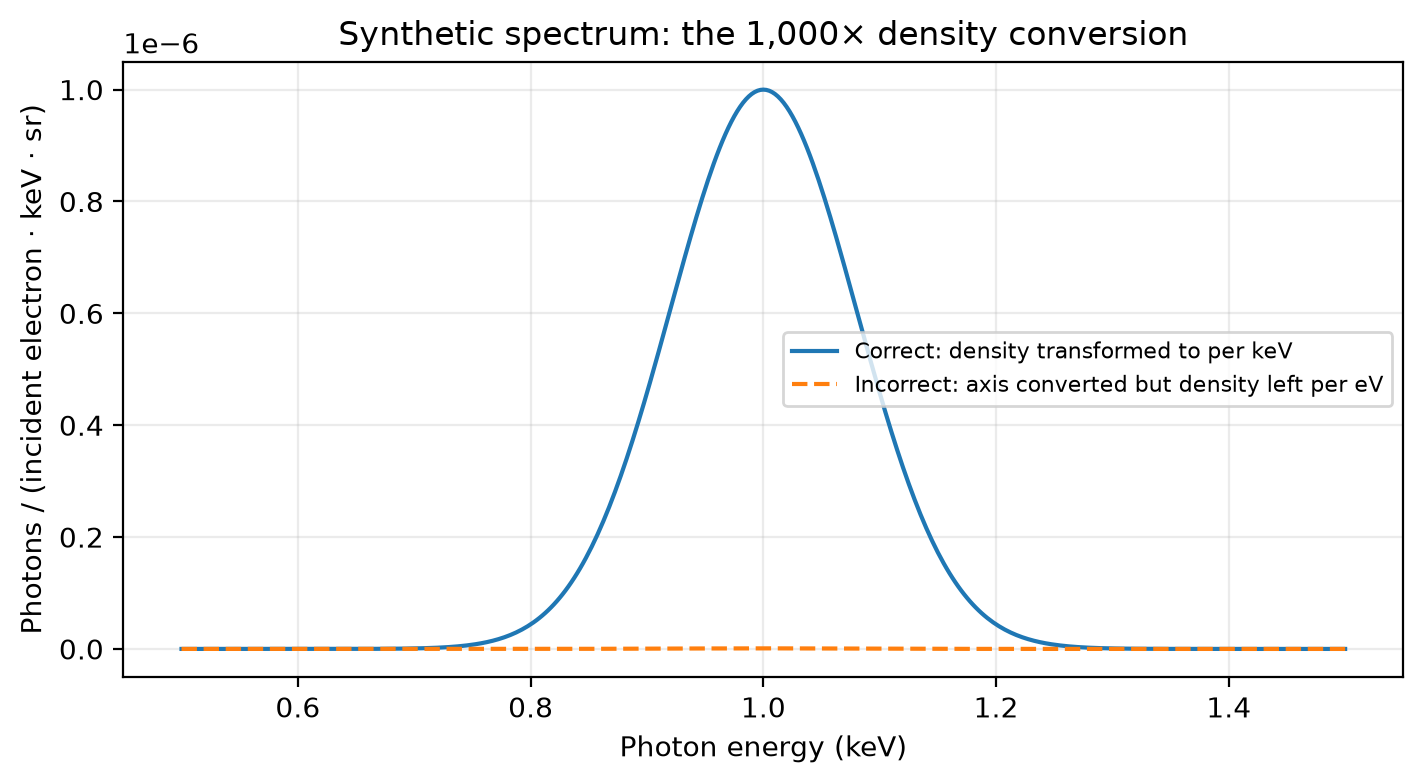

In [ ]:
fig_density, ax_density = plt.subplots(figsize=(7, 3.8), layout="constrained")
energy_keV = in_keV.photon_energy.magnitude
ax_density.plot(
    energy_keV,
    in_keV.density.magnitude,
    label="Correct: density transformed to per keV",
)
ax_density.plot(
    energy_keV,
    source.density,
    "--",
    label="Incorrect: axis converted but density left per eV",
)
ax_density.set(
    xlabel="Photon energy (keV)",
    ylabel="Photons / (incident electron · keV · sr)",
    title="Synthetic spectrum: the 1,000× density conversion",
)
ax_density.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax_density.legend(fontsize=8)
ax_density.grid(alpha=0.25)
assert abs(integral_per_eV - integral_per_keV) < 1e-12
fig_density  # noqa: B018 - display the conversion comparison

## 8. Physical normalization is a separate operation

With a 0.5 pC bunch at 100 kHz, the current is 50 nA, or approximately
$3.12\times 10^{11}$ physical electrons/s. Multiplying a **source** yield
by electrons/s yields photons/(s·sr), and multiplying by an accepted
solid angle in sr yields photons/s. Neither conversion is an energy-unit
change. An exposure or detector response is another *physical* operation.

**Do not confuse:** a simulation with `FixedSampling(cxr_electrons=8192)`
samples **8,192 numerical histories**, not 8,192 physical electrons per
bunch. When converting density and counts, also distinguish node-sampled
**per-energy density** from bin-integrated **event counts**: changing an
energy bin's units does not multiply its photon count.

In [ ]:
# The elementary charge in C is exact in the 2019 SI.
elementary_charge = 1.602176634e-19 * ureg.coulomb
electrons_per_s = (average_current / elementary_charge).to("1/s").magnitude
toy_rate_per_sr = integral_per_keV * electrons_per_s
assert np.isclose(electrons_per_s, 3.1207545e11, rtol=1e-6)
physical_scaling = {
    "mean current (nA)": average_current.to("nA").magnitude,
    "physical electrons/s": electrons_per_s,
    "synthetic photon rate/(s sr)": toy_rate_per_sr,
}
print(
    *(f"{k}: {v}" for k, v in physical_scaling.items()), sep="\n"
)  # display physically scaled illustrative rates

mean current (nA): 49.99999999999999
physical electrons/s: 312075453723.03815
synthetic photon rate/(s sr): 62580.5724638673


## What to remember

**At configuration boundaries:** prefer the semantic quantity API, e.g.
`Beam(kinetic_energy=30 * ureg.keV, ...)`. **At legacy numeric boundaries:**
respect explicit field units, e.g. `energy_keV=30` or
`thickness_ang=1000`. **For read-back:** semantic quantity properties and
`SpectralDensity.quantify()` are opt-in; ordinary result arrays and saved
records remain numeric. `to_energy()` changes *both* energy nodes and
density; flux-normalization choices such as `"detector"` do something else.

**Try:** switch the beam's input energy to `30_000 * ureg.eV`; switch the
target from `100 * ureg.nm` to `1_000 * ureg.angstrom`; and convert the
synthetic spectrum to MeV. Each change should preserve the same physical
result when the associated density units are converted correctly.

Next: [Your first X-ray spectrum](01-first-spectrum.ipynb),
[Understanding simulation results](02-understanding-results.ipynb),
[Unit API reference](../../reference/python-api/units.md),
[physical-unit input policy](../../repo-design/physical-units.md), and
[quantity-result contracts](../../repo-design/quantity-output-contract.md).

## Continue learning

Next: [Your first X-ray spectrum](01-first-spectrum.ipynb),
[Understanding simulation results](02-understanding-results.ipynb), and the
[unit API reference](../../reference/python-api/units.md).

{download}`Download canonical Marimo notebook <../00a-units-and-quantities.py>`